In [1]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd

In [2]:
import pickle

In [3]:
### impacts calculated
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/imph2.pkl', 'rb') as file:
    imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/ed2.pkl', 'rb') as file:
    ed2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/rd2.pkl', 'rb') as file:
    rd2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/impp1.pkl', 'rb') as file:
    impp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/impp2.pkl', 'rb') as file:
    impp2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/rd1_51ens.pkl', 'rb') as file:
    rd1_51ens = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/rd2_51ens.pkl', 'rb') as file:
    rd2_51ens = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp3.pkl', 'rb') as file:
#    impp3 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/impp5.pkl', 'rb') as file:
    impp5 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/impp6.pkl', 'rb') as file:
    impp6 = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp7.pkl', 'rb') as file:
#    impp7 = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/exp_dict.pkl', 'rb') as file:
    exp_dict = pickle.load(file)

In [4]:
imph2

{'imph2_MOZ_new_Idai_20190310120000': <climada.engine.impact.Impact at 0x14ed85925a10>,
 'imph2_MOZ_new_Idai_20190311120000': <climada.engine.impact.Impact at 0x14ed84cc7cd0>,
 'imph2_MOZ_new_Idai_20190312120000': <climada.engine.impact.Impact at 0x14ed84cc7d50>,
 'imph2_MOZ_new_Idai_20190313120000': <climada.engine.impact.Impact at 0x14ed84cc7ed0>,
 'imph2_MOZ_new_Idai_20190314120000': <climada.engine.impact.Impact at 0x14ed84cdc190>}

In [5]:
import numpy as np
import pandas as pd

summary_stats = []  # ✅ Reset before appending again
affected_counts_dict = {}

for lead_time_key, impact_obj in imph2.items():
    imp_dense_imph2 = impact_obj.imp_mat.toarray()
    affected_imph2 = imp_dense_imph2 > 0.20
    affected_counts_imph2 = affected_imph2.sum(axis=1)

    stats = {
        'lead_time': lead_time_key,
        'min_affected': int(np.min(affected_counts_imph2)),
        'median_affected': int(np.median(affected_counts_imph2)),
        'max_affected': int(np.max(affected_counts_imph2)),
        'mean_affected': round(np.mean(affected_counts_imph2)),
        'affected_array': affected_counts_imph2
    }
    summary_stats.append(stats)
    affected_counts_dict[lead_time_key] = affected_counts_imph2

summary_df = pd.DataFrame(summary_stats)
summary_df = summary_df.sort_values(by='lead_time')

In [6]:
# Define the mapping dictionary
rename_dict = {
    'imph2_MOZ_new_Idai_20190310120000': '4 days',
    'imph2_MOZ_new_Idai_20190311120000': '3 days',
    'imph2_MOZ_new_Idai_20190312120000': '2 days',
    'imph2_MOZ_new_Idai_20190313120000': '1 day',
    'imph2_MOZ_new_Idai_20190314120000': 'landfall'
}

# Apply the mapping to the 'lead_time' column
summary_df['lead_time'] = summary_df['lead_time'].replace(rename_dict)

In [7]:
summary_df

,lead_time,min_affected,median_affected,max_affected,mean_affected,affected_array
0,4 days,0,65,115,62,"[66, 42, 74, 74, 88, 62, 71, 96, 38, 38, 54, 7..."
1,3 days,38,67,107,67,"[66, 68, 78, 52, 52, 89, 56, 49, 63, 82, 56, 7..."
2,2 days,50,69,95,70,"[63, 52, 77, 60, 76, 73, 84, 80, 73, 65, 64, 5..."
3,1 day,49,73,96,74,"[79, 69, 80, 83, 49, 68, 80, 79, 78, 62, 76, 6..."
4,landfall,53,74,93,74,"[72, 68, 74, 91, 68, 80, 80, 70, 81, 71, 64, 6..."


In [8]:
# Create a new dictionary with renamed keys using the same rename_dict
affected_counts_dict = {
    rename_dict.get(key, key): value for key, value in affected_counts_dict.items()
}

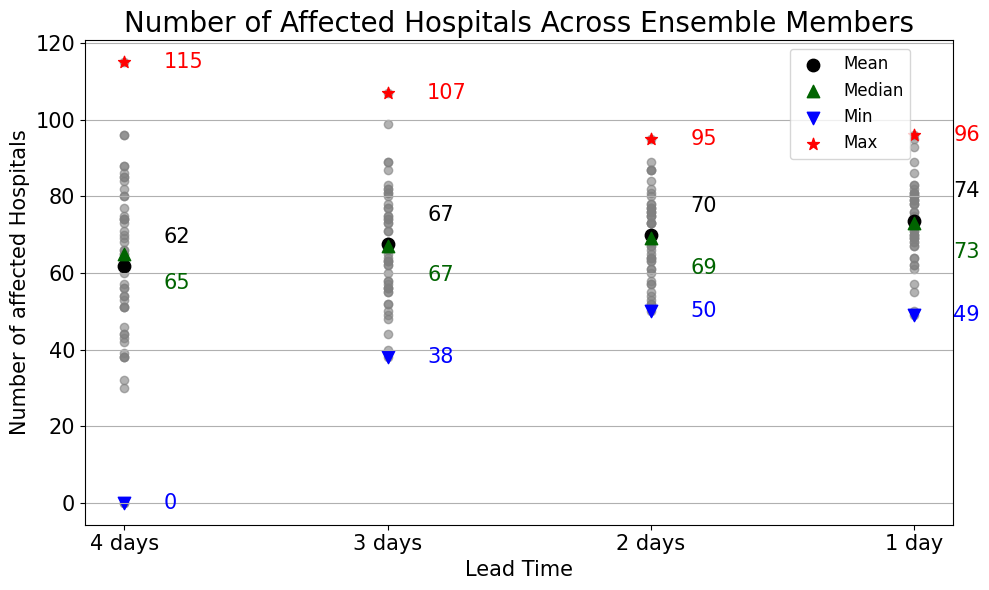

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Data preparation
lead_times = ['4 days', '3 days', '2 days', '1 day']
dot_data = [affected_counts_dict[lt] for lt in lead_times]

plt.figure(figsize=(10, 6))

for i, (lt, values) in enumerate(zip(lead_times, dot_data)):
    x = np.full_like(values, i + 1)  # X-axis position

    # Plot gray dots for all ensemble members
    plt.scatter(x, values, color='gray', alpha=0.6, label='_nolegend_')

    # Calculate statistics
    mean = np.mean(values)
    median = np.median(values)
    min_val = np.min(values)
    max_val = np.max(values)

    # Plot statistics
    plt.scatter(i + 1, mean, color='black', s=80, marker='o', label='Mean' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, median, color='darkgreen', s=80, marker='^', label='Median' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, min_val, color='blue', s=80, marker='v', label='Min' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, max_val, color='red', s=80, marker='*', label='Max' if i == 0 else "_nolegend_")

    # Add annotations with spacing to avoid overlap
    plt.text(i + 1 + 0.15, mean + 5, f'{mean:.0f}', va='bottom', fontsize=15, color='black')
    plt.text(i + 1 + 0.15, median - 5, f'{median:.0f}', va='top', fontsize=15, color='darkgreen')
    plt.text(i + 1 + 0.15, min_val, f'{min_val:.0f}', va='center', fontsize=15, color='blue')
    plt.text(i + 1 + 0.15, max_val, f'{max_val:.0f}', va='center', fontsize=15, color='red')

# Formatting
plt.xticks(ticks=range(1, len(lead_times) + 1), labels=lead_times, fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel("Lead Time", fontsize=15)
plt.ylabel("Number of affected Hospitals", fontsize=15)
plt.title("Number of Affected Hospitals Across Ensemble Members", fontsize=20)
plt.grid(axis='y')
plt.legend(loc='upper right', bbox_to_anchor=(0.96, 1), fontsize=12)

# Save and show
plt.tight_layout()
plt.savefig("/cluster/home/gespejo/MOZ_struc_plots_Idai/affected_hospitals_by_lead_time.png", dpi=600)
plt.show()

In [10]:
### NEW PLOT

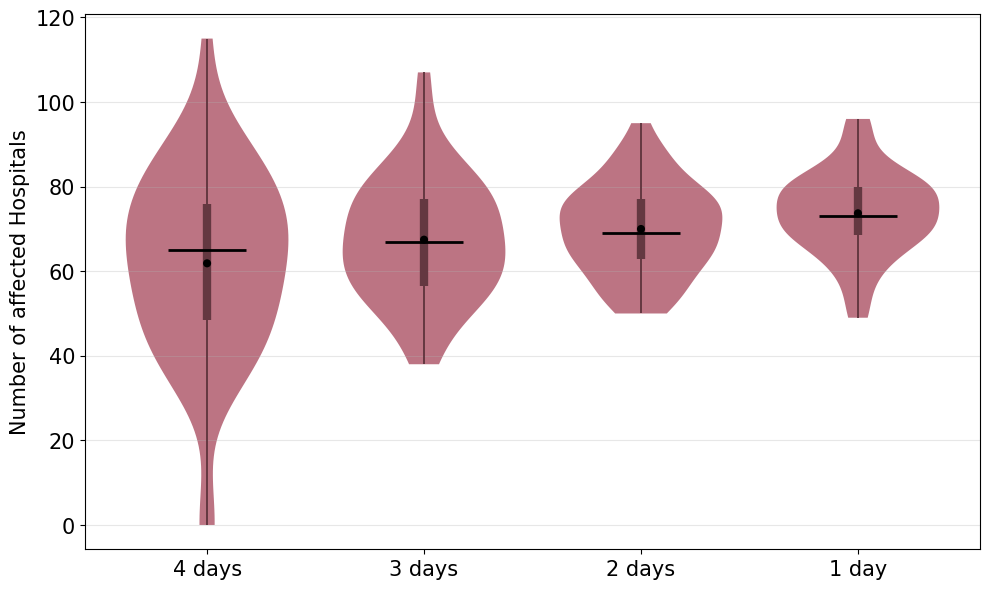

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors as mcolors

def darker(color, factor=0.55):
    r, g, b = mcolors.to_rgb(color)
    return (r*factor, g*factor, b*factor)

# Data
lead_times = ['4 days', '3 days', '2 days', '1 day']
dot_data = [affected_counts_dict[lt] for lt in lead_times]

# Single color for all violins
SINGLE_COLOR = '#B56576'              # your second color
STATS_COLOR  = darker(SINGLE_COLOR)   # darker for whiskers/IQR

fig, ax = plt.subplots(figsize=(10, 6))

vp = ax.violinplot(
    dot_data,
    positions=np.arange(1, len(lead_times) + 1),
    widths=0.75,
    showmeans=False, showmedians=False, showextrema=False
)

# Same color for all violins
for b in vp['bodies']:
    b.set_facecolor(SINGLE_COLOR)
    b.set_edgecolor('none')
    b.set_alpha(0.9)

# Overlay stats (whiskers, IQR, median, mean)
for i, y in enumerate(dot_data, start=1):
    y = np.asarray(y, dtype=float)
    y = y[~np.isnan(y)]
    if y.size == 0:
        continue

    q1, med, q3 = np.percentile(y, [25, 50, 75])
    whisk_lo, whisk_hi = np.min(y), np.max(y)
    mean = np.mean(y)

    ax.vlines(i, whisk_lo, whisk_hi, color=STATS_COLOR, linewidth=1.4, zorder=3)  # whiskers
    ax.vlines(i, q1, q3,           color=STATS_COLOR, linewidth=6,   zorder=4)    # IQR
    ax.hlines(med, i-0.18, i+0.18, color='black',     linewidth=2.0, zorder=5)    # median
    ax.scatter(i, mean, s=34, c='black', edgecolors='none', zorder=6)             # mean

# Formatting
ax.set_xticks(range(1, len(lead_times) + 1))
ax.set_xticklabels(lead_times, fontsize=15)
ax.tick_params(axis='y', labelsize=15)
ax.set_ylabel("Number of affected Hospitals", fontsize=15)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Idai/Affected_hospitals_violyn.png",
           dpi=1500, bbox_inches="tight")
plt.show()

In [12]:
###For schools 

In [13]:
import numpy as np
import pandas as pd

summary_stats_ed2 = []
affected_counts_dict_ed2 = {}

for lead_time_key, impact_obj in ed2.items():
    imp_dense_ed2 = impact_obj.imp_mat.toarray()
    affected_ed2 = imp_dense_ed2 > 0.20
    affected_counts_ed2 = affected_ed2.sum(axis=1)

    stats = {
        'lead_time': lead_time_key,
        'min_affected': int(np.min(affected_counts_ed2)),
        'median_affected': int(np.median(affected_counts_ed2)),
        'max_affected': int(np.max(affected_counts_ed2)),
        'mean_affected': round(np.mean(affected_counts_ed2)),
        'affected_array': affected_counts_ed2
    }
    summary_stats_ed2.append(stats)
    affected_counts_dict_ed2[lead_time_key] = affected_counts_ed2

summary_df_ed2 = pd.DataFrame(summary_stats_ed2)
summary_df_ed2 = summary_df_ed2.sort_values(by='lead_time')

In [14]:
ed2

{'ed2_MOZ_new_Idai_20190310120000': <climada.engine.impact.Impact at 0x14ed85572210>,
 'ed2_MOZ_new_Idai_20190311120000': <climada.engine.impact.Impact at 0x14ed84cdc710>,
 'ed2_MOZ_new_Idai_20190312120000': <climada.engine.impact.Impact at 0x14ed84cdc790>,
 'ed2_MOZ_new_Idai_20190313120000': <climada.engine.impact.Impact at 0x14ed84cdc8d0>,
 'ed2_MOZ_new_Idai_20190314120000': <climada.engine.impact.Impact at 0x14ed84cdca50>}

In [15]:
# Define the mapping dictionary
rename_dict = {
    'ed2_MOZ_new_Idai_20190310120000': '4 days',
    'ed2_MOZ_new_Idai_20190311120000': '3 days',
    'ed2_MOZ_new_Idai_20190312120000': '2 days',
    'ed2_MOZ_new_Idai_20190313120000': '1 day',
    'ed2_MOZ_new_Idai_20190314120000': 'landfall',
}

# Apply the mapping to the 'lead_time' column
summary_df_ed2['lead_time'] = summary_df_ed2['lead_time'].replace(rename_dict)

In [16]:
summary_df_ed2

,lead_time,min_affected,median_affected,max_affected,mean_affected,affected_array
0,4 days,0,66,103,66,"[91, 57, 93, 31, 80, 58, 96, 87, 11, 34, 63, 6..."
1,3 days,29,70,101,74,"[68, 74, 95, 56, 73, 98, 56, 55, 66, 93, 65, 7..."
2,2 days,12,78,102,78,"[65, 66, 68, 72, 95, 78, 93, 77, 60, 65, 91, 7..."
3,1 day,63,92,103,86,"[89, 93, 96, 97, 63, 91, 92, 93, 96, 74, 93, 7..."
4,landfall,65,93,98,92,"[93, 92, 93, 96, 92, 93, 96, 93, 90, 96, 90, 9..."


In [17]:
# Create a new dictionary with renamed keys using the same rename_dict
affected_counts_dict_ed2 = {
    rename_dict.get(key, key): value for key, value in affected_counts_dict_ed2.items()
}

In [18]:
###plotting schools 

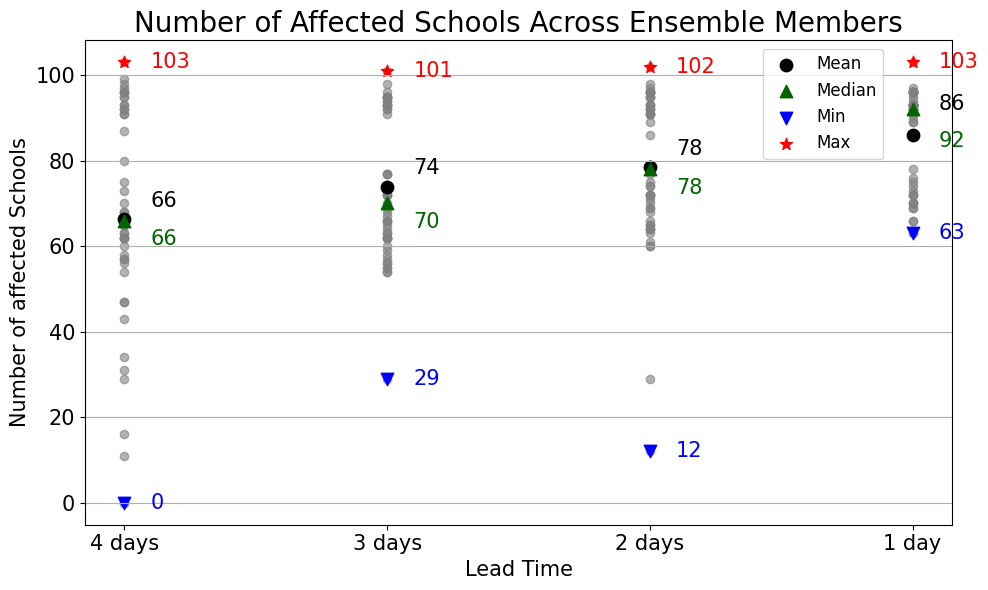

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Data preparation
lead_times = ['4 days', '3 days', '2 days', '1 day']
dot_data = [affected_counts_dict_ed2[lt] for lt in lead_times]

plt.figure(figsize=(10, 6))

for i, (lt, values) in enumerate(zip(lead_times, dot_data)):
    x = np.full_like(values, i + 1)  # Position on x-axis
    
    # Basic gray dots
    plt.scatter(x, values, color='gray', alpha=0.6, label='_nolegend_')

    # Statistics
    mean = np.mean(values)
    median = np.median(values)
    min_val = np.min(values)
    max_val = np.max(values)

    # Plot statistics
    plt.scatter(i + 1, mean, color='black', s=80, marker='o', label='Mean' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, median, color='darkgreen', s=80, marker='^', label='Median' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, min_val, color='blue', s=80, marker='v', label='Min' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, max_val, color='red', s=80, marker='*', label='Max' if i == 0 else "_nolegend_")

    # Offset adjustment (avoid overlap in last column)
    offset_mean = 5 if i == 3 else 2
    offset_median = -5 if i == 3 else -2

    # Add annotations
    plt.text(i + 1 + 0.1, mean + offset_mean, f'{mean:.0f}', va='bottom', fontsize=15, color='black')
    plt.text(i + 1 + 0.1, median + offset_median, f'{median:.0f}', va='top', fontsize=15, color='darkgreen')
    plt.text(i + 1 + 0.1, min_val, f'{min_val:.0f}', va='center', fontsize=15, color='blue')
    plt.text(i + 1 + 0.1, max_val, f'{max_val:.0f}', va='center', fontsize=15, color='red')

# Aesthetics
plt.xticks(ticks=range(1, len(lead_times) + 1), labels=lead_times, fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel("Lead Time", fontsize=15)
plt.ylabel("Number of affected Schools", fontsize=15)
plt.title("Number of Affected Schools Across Ensemble Members", fontsize=20)
plt.grid(axis='y')
plt.legend(loc='upper right', bbox_to_anchor=(0.93, 1), fontsize=12)

# Save and show
plt.tight_layout()
plt.savefig("/cluster/home/gespejo/MOZ_struc_plots_Idai/affected_schools_by_lead_time.png", dpi=600)
plt.show()

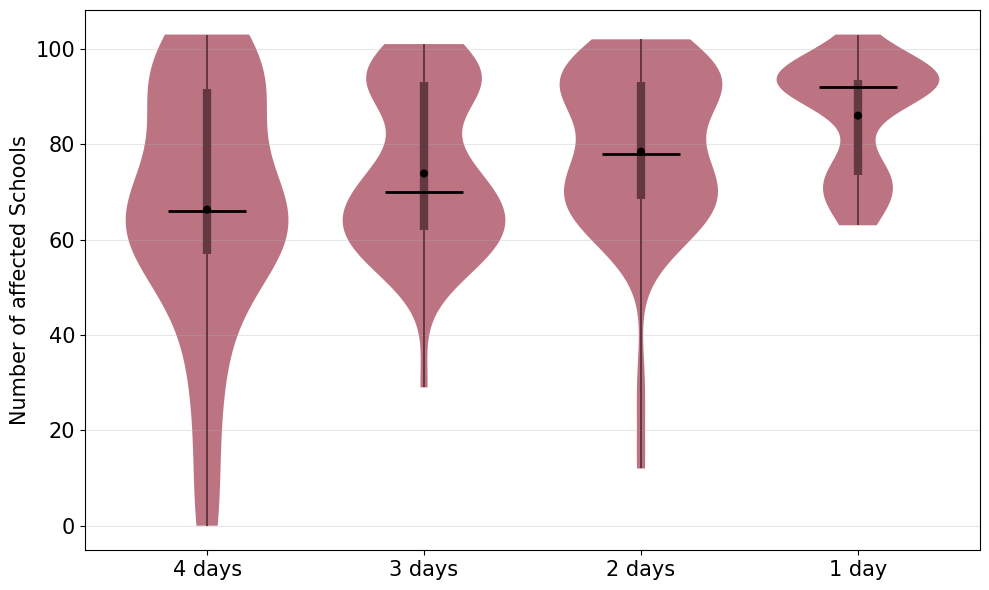

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors as mcolors

def darker(color, factor=0.55):
    r, g, b = mcolors.to_rgb(color)
    return (r*factor, g*factor, b*factor)

# Data
lead_times = ['4 days', '3 days', '2 days', '1 day']
dot_data = [affected_counts_dict_ed2[lt] for lt in lead_times]

# Single uniform color (your 2nd color)
SINGLE_COLOR = '#B56576'
STATS_COLOR  = darker(SINGLE_COLOR)

fig, ax = plt.subplots(figsize=(10, 6))

vp = ax.violinplot(
    dot_data,
    positions=np.arange(1, len(lead_times) + 1),
    widths=0.75,
    showmeans=False, showmedians=False, showextrema=False
)

# Same color for all violins
for b in vp['bodies']:
    b.set_facecolor(SINGLE_COLOR)
    b.set_edgecolor('none')
    b.set_alpha(0.9)

# Stats (whiskers, IQR, median, mean)
for i, y in enumerate(dot_data, start=1):
    y = np.asarray(y, dtype=float)
    y = y[~np.isnan(y)]
    if y.size == 0:
        continue
    q1, med, q3 = np.percentile(y, [25, 50, 75])
    whisk_lo, whisk_hi = np.min(y), np.max(y)
    mean = np.mean(y)

    ax.vlines(i, whisk_lo, whisk_hi, color=STATS_COLOR, linewidth=1.4, zorder=3)  # whiskers
    ax.vlines(i, q1, q3,           color=STATS_COLOR, linewidth=6,   zorder=4)    # IQR
    ax.hlines(med, i-0.18, i+0.18, color='black',     linewidth=2.0, zorder=5)    # median
    ax.scatter(i, mean, s=34, c='black', edgecolors='none', zorder=6)             # mean

# Formatting
ax.set_xticks(range(1, len(lead_times) + 1))
ax.set_xticklabels(lead_times, fontsize=15)
ax.tick_params(axis='y', labelsize=15)
ax.set_ylabel("Number of affected Schools", fontsize=15)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
#fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Idai/Affected_schools_violyn.png",
#            dpi=1500, bbox_inches="tight")
plt.show()

In [21]:
###roads
def join_road_exp_51ens(ens_51, exposure_gdf):
    results = {}
    for key, df in ens_51.items():
        df = df.reset_index(drop=True)
        exposure_gdf = exposure_gdf.reset_index(drop=True)

        if len(df) == len(exposure_gdf):
            df['osm_id'] = exposure_gdf['osm_id']
        else:
            raise ValueError(f"Mismatch in DataFrame lengths for key: {key}")

        grouped = df.groupby('osm_id').mean()
        first_geometry = exposure_gdf.drop_duplicates(subset=['osm_id'])[['osm_id', 'geometry_orig']]
        merged_grouped = grouped.merge(first_geometry, on='osm_id', how='left')

        column_range = list(range(51))
        merged_grouped['mean_impact'] = merged_grouped[column_range].mean(axis=1)

        # Keep all ensemble columns, 'mean_impact', and 'geometry_orig'
        ensemble_cols = [col for col in merged_grouped.columns if isinstance(col, int) or col == 'mean_impact']
        final_cols = ['osm_id'] + ensemble_cols + ['geometry_orig']
        final_result = merged_grouped[final_cols]

        geo_df = gpd.GeoDataFrame(final_result, geometry='geometry_orig')
        geo_df.set_crs(epsg=4326, inplace=True)

        results[key] = geo_df

    return results

In [22]:
rd2_mimpact = join_road_exp_51ens(rd2_51ens, exp_dict['exp_rd2_MOZ'].gdf)
rd2_mimpact

{'20190310120000':             osm_id    0    1    2    3    4    5    6    7    8  ...   43  \
 0       1000094235  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  0.0   
 1       1000094236  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  0.0   
 2       1000094237  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  0.0   
 3       1000094238  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  0.0   
 4       1000094239  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  0.0   
 ...            ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...  ...   
 267272   999858614  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  0.0   
 267273   999859262  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  0.0   
 267274   999860028  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  0.0   
 267275   999865566  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  0.0   
 267276   999866041  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  ...  0.0   
 
          44   45   46   47   48   49   50  

In [23]:
### scale 
def mimpact_cols_scale(data_dict, divisor):
    """
    Scales columns 0 to 50 and 'mean_impact' in all DataFrames within a dictionary.

    Parameters:
    data_dict (dict): Dictionary containing the DataFrames.
    divisor (int or float): Value by which to divide the column values.

    Returns:
    None; the operation modifies the DataFrames in place.
    """
    for key, df in data_dict.items():
        # Select columns that are integers from 0 to 50 or 'mean_impact'
        cols_to_scale = [col for col in df.columns if 
                         (isinstance(col, int) and 0 <= col <= 50) or col == 'mean_impact']
        
        # Only scale if those columns are present
        if cols_to_scale:
            df[cols_to_scale] = df[cols_to_scale] / divisor
        else:
            print(f"No matching columns found in DataFrame for key '{key}'.")

In [24]:
mimpact_cols_scale(rd2_mimpact, 500.0)

In [25]:
rd2_mimpact ['20190314120000']

,osm_id,0,1,2,3,4,5,6,7,8,...,43,44,45,46,47,48,49,50,mean_impact,geometry_orig
0,1000094235,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"LINESTRING (34.85737 -12.07814, 34.85806 -12.0..."
1,1000094236,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"LINESTRING (34.86028 -12.07356, 34.86064 -12.0..."
2,1000094237,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"LINESTRING (34.86461 -12.07019, 34.86546 -12.0..."
3,1000094238,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"LINESTRING (34.86969 -12.06645, 34.87077 -12.0..."
4,1000094239,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"LINESTRING (34.87264 -12.06299, 34.87296 -12.0..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267272,999858614,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"LINESTRING (36.20637 -16.50687, 36.20649 -16.5..."
267273,999859262,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"LINESTRING (36.21017 -16.50493, 36.21046 -16.5..."
267274,999860028,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"LINESTRING (36.21611 -16.50442, 36.21608 -16.5..."
267275,999865566,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"LINESTRING (36.21280 -16.50162, 36.21288 -16.5..."


In [26]:
# Your rename_dict
rename_dict = {
    '20190310120000': '4 days',
    '20190311120000': '3 days',
    '20190312120000': '2 days',
    '20190313120000': '1 day',
    '20190314120000': 'landfall'
}

# Create a new dictionary with renamed keys
rd2_mimpact= {
    rename_dict.get(k, k): v for k, v in rd2_mimpact.items()
}

In [27]:
import numpy as np
import pandas as pd

summary_stats_rd2 = []
affected_counts_dict_rd2 = {}  # <- This will store arrays of affected roads per lead time

for lead_time_key, gdf in rd2_mimpact.items():
    ens_cols = [col for col in gdf.columns if isinstance(col, int) and 0 <= col <= 50]
    impact_array = gdf[ens_cols].values  # Shape: (n_roads, 51)

    affected = impact_array >= 0.20
    affected_counts = affected.sum(axis=0)  # Shape: (51,) — number of affected roads per ensemble

    # Store in dictionary
    affected_counts_dict_rd2[lead_time_key] = affected_counts

    # Compute summary statistics
    stats = {
        'lead_time': lead_time_key,
        'min_affected': int(np.min(affected_counts)),
        'median_affected': int(np.median(affected_counts)),
        'max_affected': int(np.max(affected_counts)),
        'mean_affected': round(np.mean(affected_counts))
    }
    summary_stats_rd2.append(stats)

summary_df_rd2 = pd.DataFrame(summary_stats_rd2)
lead_time_order = ['4 days', '3 days', '2 days', '1 day', 'landfall']
summary_df_rd2['lead_time'] = pd.Categorical(summary_df_rd2['lead_time'], categories=lead_time_order, ordered=True)
summary_df_rd2 = summary_df_rd2.sort_values(by='lead_time')

In [28]:
summary_df_rd2

,lead_time,min_affected,median_affected,max_affected,mean_affected
0,4 days,0,32070,61514,29307
1,3 days,17484,33366,41878,32424
2,2 days,7663,34437,40588,33506
3,1 day,27136,37881,42955,36706
4,landfall,31726,38718,42721,38315


In [29]:
###plotting roads affected 

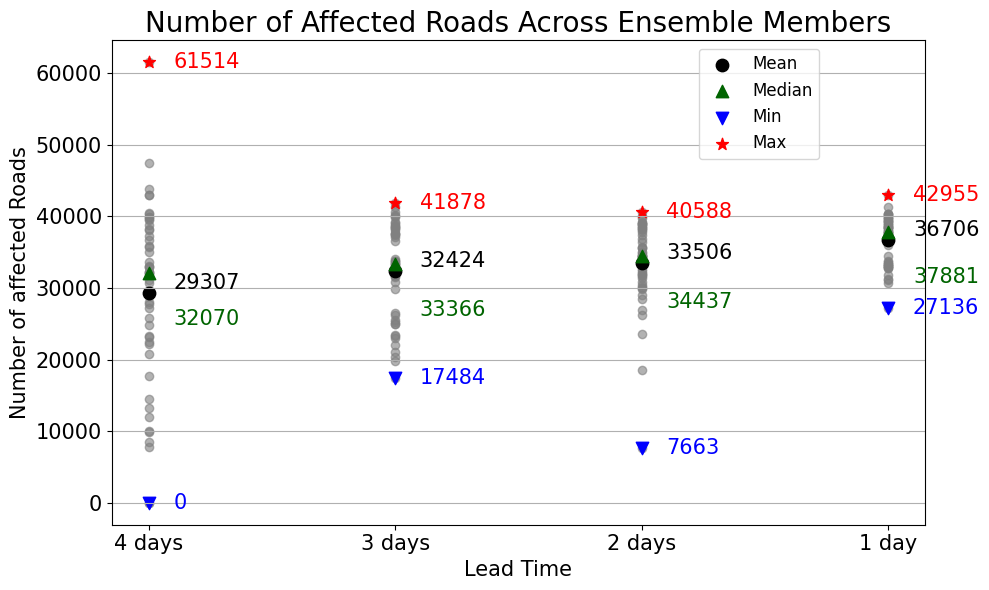

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Data preparation
lead_times = ['4 days', '3 days', '2 days', '1 day']
dot_data = [affected_counts_dict_rd2[lt] for lt in lead_times]

plt.figure(figsize=(10, 6))

# Plot all points
for i, (lt, values) in enumerate(zip(lead_times, dot_data)):
    x = np.full_like(values, i + 1)

    # Ensemble gray dots
    plt.scatter(x, values, color='gray', alpha=0.6, label='_nolegend_')

    # Statistics
    mean = np.mean(values)
    median = np.median(values)
    min_val = np.min(values)
    max_val = np.max(values)

    # Plot statistics
    plt.scatter(i + 1, mean, color='black', s=80, marker='o', label='Mean' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, median, color='darkgreen', s=80, marker='^', label='Median' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, min_val, color='blue', s=80, marker='v', label='Min' if i == 0 else "_nolegend_")
    plt.scatter(i + 1, max_val, color='red', s=80, marker='*', label='Max' if i == 0 else "_nolegend_")

    # Annotated text with spacing
    plt.text(i + 1 + 0.1, mean , f'{mean:.0f}', va='bottom', fontsize=15, color='black')
    plt.text(i + 1 + 0.1, median - 5000, f'{median:.0f}', va='top', fontsize=15, color='darkgreen')
    plt.text(i + 1 + 0.1, min_val, f'{min_val:.0f}', va='center', fontsize=15, color='blue')
    plt.text(i + 1 + 0.1, max_val, f'{max_val:.0f}', va='center', fontsize=15, color='red')

# Formatting
plt.xticks(ticks=range(1, len(lead_times) + 1), labels=lead_times, fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel("Lead Time", fontsize=15)
plt.ylabel("Number of affected Roads", fontsize=15)
plt.title("Number of Affected Roads Across Ensemble Members", fontsize=20)
plt.grid(axis='y')
plt.legend(loc='upper right', bbox_to_anchor=(0.88, 1), fontsize=12)

# Save and show
plt.tight_layout()
plt.savefig("/cluster/home/gespejo/MOZ_struc_plots_Idai/affected_roads_by_lead_time.png", dpi=600)
plt.show()

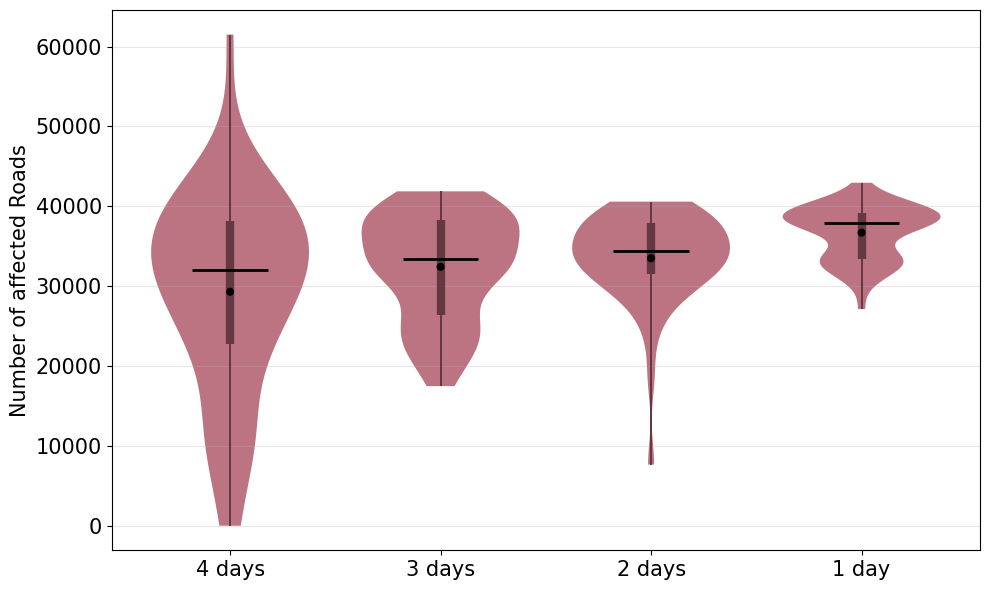

In [31]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors as mcolors

def darker(color, factor=0.55):
    r, g, b = mcolors.to_rgb(color)
    return (r*factor, g*factor, b*factor)

# Data
lead_times = ['4 days', '3 days', '2 days', '1 day']
dot_data = [affected_counts_dict_rd2[lt] for lt in lead_times]

# Single color for all violins (your 2nd color)
SINGLE_COLOR = '#B56576'
STATS_COLOR  = darker(SINGLE_COLOR)

fig, ax = plt.subplots(figsize=(10, 6))

vp = ax.violinplot(
    dot_data,
    positions=np.arange(1, len(lead_times) + 1),
    widths=0.75,
    showmeans=False, showmedians=False, showextrema=False
)

# same color for all violins
for b in vp['bodies']:
    b.set_facecolor(SINGLE_COLOR)
    b.set_edgecolor('none')
    b.set_alpha(0.9)

# whiskers / IQR / median / mean
for i, y in enumerate(dot_data, start=1):
    y = np.asarray(y, dtype=float)
    y = y[~np.isnan(y)]
    if y.size == 0:
        continue
    q1, med, q3 = np.percentile(y, [25, 50, 75])
    whisk_lo, whisk_hi = np.min(y), np.max(y)
    mean = np.mean(y)

    ax.vlines(i, whisk_lo, whisk_hi, color=STATS_COLOR, linewidth=1.4, zorder=3)  # whiskers
    ax.vlines(i, q1, q3,           color=STATS_COLOR, linewidth=6,   zorder=4)    # IQR
    ax.hlines(med, i-0.18, i+0.18, color='black',     linewidth=2.0, zorder=5)    # median
    ax.scatter(i, mean, s=34, c='black', edgecolors='none', zorder=6)             # mean

# formatting
ax.set_xticks(range(1, len(lead_times) + 1))
ax.set_xticklabels(lead_times, fontsize=15)
ax.tick_params(axis='y', labelsize=15)
ax.set_ylabel("Number of affected Roads", fontsize=15)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Idai/Affected_roads_violyn.png",
            dpi=1500, bbox_inches="tight")
plt.show()

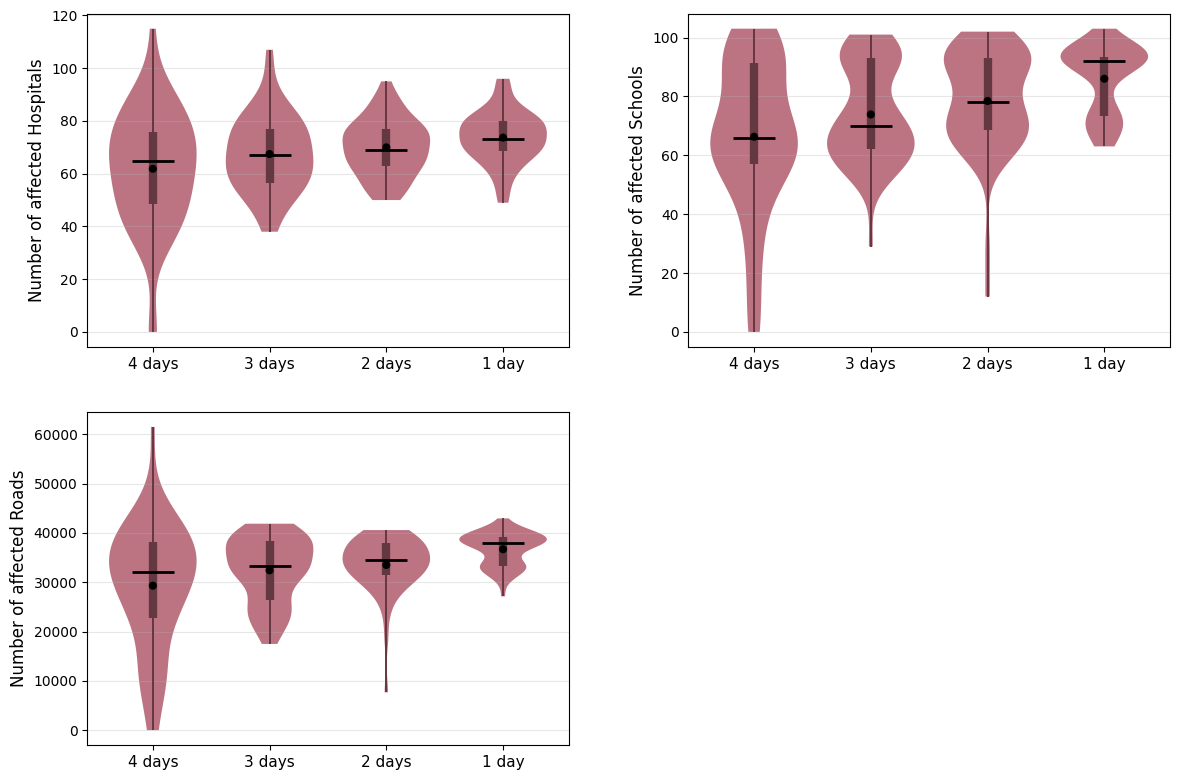

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors

# --- helpers ---
def darker(color, factor=0.55):
    r, g, b = mcolors.to_rgb(color)
    return (r*factor, g*factor, b*factor)

# --- inputs (you already have these dicts) ---
lead_times = ['4 days', '3 days', '2 days', '1 day']
data_a = [affected_counts_dict[lt]     for lt in lead_times]   # Hospitals
data_b = [affected_counts_dict_ed2[lt] for lt in lead_times]   # Schools
data_c = [affected_counts_dict_rd2[lt] for lt in lead_times]   # Roads

SINGLE_COLOR = '#B56576'           # uniform color for all violins
STATS_COLOR  = darker(SINGLE_COLOR)

def violin_on(ax, dot_data, ylabel, lead_times):
    positions = np.arange(1, len(dot_data) + 1)

    # violins
    vp = ax.violinplot(
        dot_data,
        positions=positions,
        widths=0.75,
        showmeans=False, showmedians=False, showextrema=False
    )
    for b in vp['bodies']:
        b.set_facecolor(SINGLE_COLOR)
        b.set_edgecolor('none')
        b.set_alpha(0.9)

    # stats (whiskers / IQR / median / mean)
    for i, y in zip(positions, dot_data):
        y = np.asarray(y, float)
        y = y[~np.isnan(y)]
        if y.size == 0:
            continue
        q1, med, q3 = np.percentile(y, [25, 50, 75])
        whisk_lo, whisk_hi = np.min(y), np.max(y)
        mean = np.mean(y)

        ax.vlines(i, whisk_lo, whisk_hi, color=STATS_COLOR, linewidth=1.4, zorder=3)
        ax.vlines(i, q1, q3,           color=STATS_COLOR, linewidth=6,   zorder=4)
        ax.hlines(med, i-0.18, i+0.18, color='black',     linewidth=2.0, zorder=5)
        ax.scatter(i, mean, s=34, c='black', edgecolors='none', zorder=6)

    # x/y labels & grid
    ax.set_xticks(positions)
    ax.set_xticklabels(lead_times, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.grid(axis='y', alpha=0.3)

# --- figure: 2x2 grid (a TL, b TR, c BL, BR empty) ---
fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True, constrained_layout=True)

# widen the middle gaps (more white space between subplots)
fig.set_constrained_layout_pads(
    w_pad=0.20, h_pad=0.20,   # padding around the figure (inches)
    wspace=0.10, hspace=0.10  # extra space between subplots
)

violin_on(axs[0,0], data_a, "Number of affected Hospitals", lead_times)
violin_on(axs[0,1], data_b, "Number of affected Schools",  lead_times)
violin_on(axs[1,0], data_c, "Number of affected Roads",    lead_times)
axs[1,1].axis('off')  # bottom-right empty

# force x-tick labels to show on ALL subplots (sharex hides top row by default)
positions = np.arange(1, len(lead_times) + 1)
for ax in (axs[0,0], axs[0,1], axs[1,0]):
    ax.set_xticks(positions)
    ax.set_xticklabels(lead_times, fontsize=11)
    ax.tick_params(axis='x', labelbottom=True)

# OPTIONAL: panel letters
# axs[0,0].text(-0.15, 1.03, "a)", transform=axs[0,0].transAxes, fontsize=12, fontweight='bold')
# axs[0,1].text(-0.15, 1.03, "b)", transform=axs[0,1].transAxes, fontsize=12, fontweight='bold')
# axs[1,0].text(-0.15, 1.03, "c)", transform=axs[1,0].transAxes, fontsize=12, fontweight='bold')

fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Idai/violins_2x2_Idai.png",
            dpi=1500, bbox_inches="tight")
plt.show()